In [10]:
# Install commonly used packages for this notebook environment (only needed the first time)
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
# Additional installs for model training/runtime (keeps environment consistent)
%pip install xgboost scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
# Cell: Import libraries, configure warnings, and load dataset into `df`.
# This cell brings in plotting, ML and util libraries and reads the CSV into a DataFrame.
# =============================================
# STEP 1: Import Libraries & Load Dataset
# =============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_csv('data/kc_house_data.csv')

# Display info
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


Missing values:
 id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


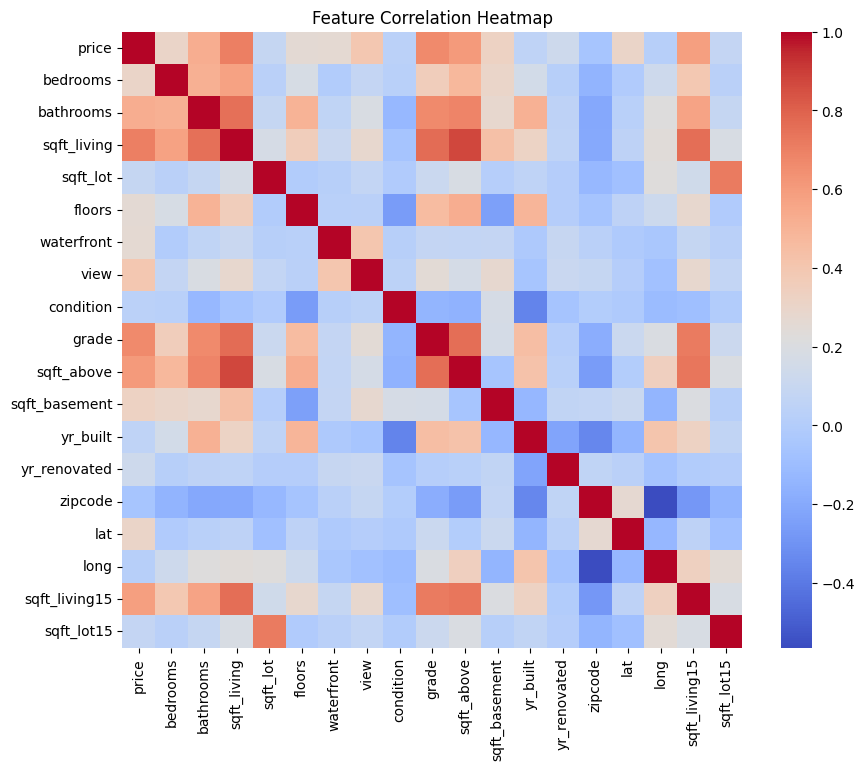

After removing outliers: (14934, 19)


In [13]:
# Cell: Exploratory Data Analysis (EDA) and initial preprocessing steps.
# Performs basic cleaning, missing value handling, descriptive stats and visualizations.
# =============================================
# STEP 2: EDA + Preprocessing
# =============================================

# Check for null values
print("Missing values:\n", df.isnull().sum())

# Drop unnecessary columns
df = df.drop(['id', 'date'], axis=1, errors='ignore')

# Handle missing values
df = df.fillna(df.median())

# Basic statistics
df.describe().T

# Correlation Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
plt.title("Feature Correlation Heatmap")
plt.show()

# Detect outliers using IQR method
numeric_cols = df.select_dtypes(include=[np.number]).columns
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

# Removing outliers beyond 1.5*IQR
df = df[~((df[numeric_cols] < (Q1 - 1.5 * IQR)) | (df[numeric_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]
print("After removing outliers:", df.shape)


Total rows: 14934, Outlier rows: 1552
Outlier counts per column:
sqft_above       372
sqft_basement    323
sqft_lot         312
sqft_living15    248
sqft_lot15       234
price            234
long             178
sqft_living      104
bedrooms           0
bathrooms          0
floors             0
grade              0
condition          0
view               0
waterfront         0
zipcode            0
yr_renovated       0
yr_built           0
lat                0
dtype: int64


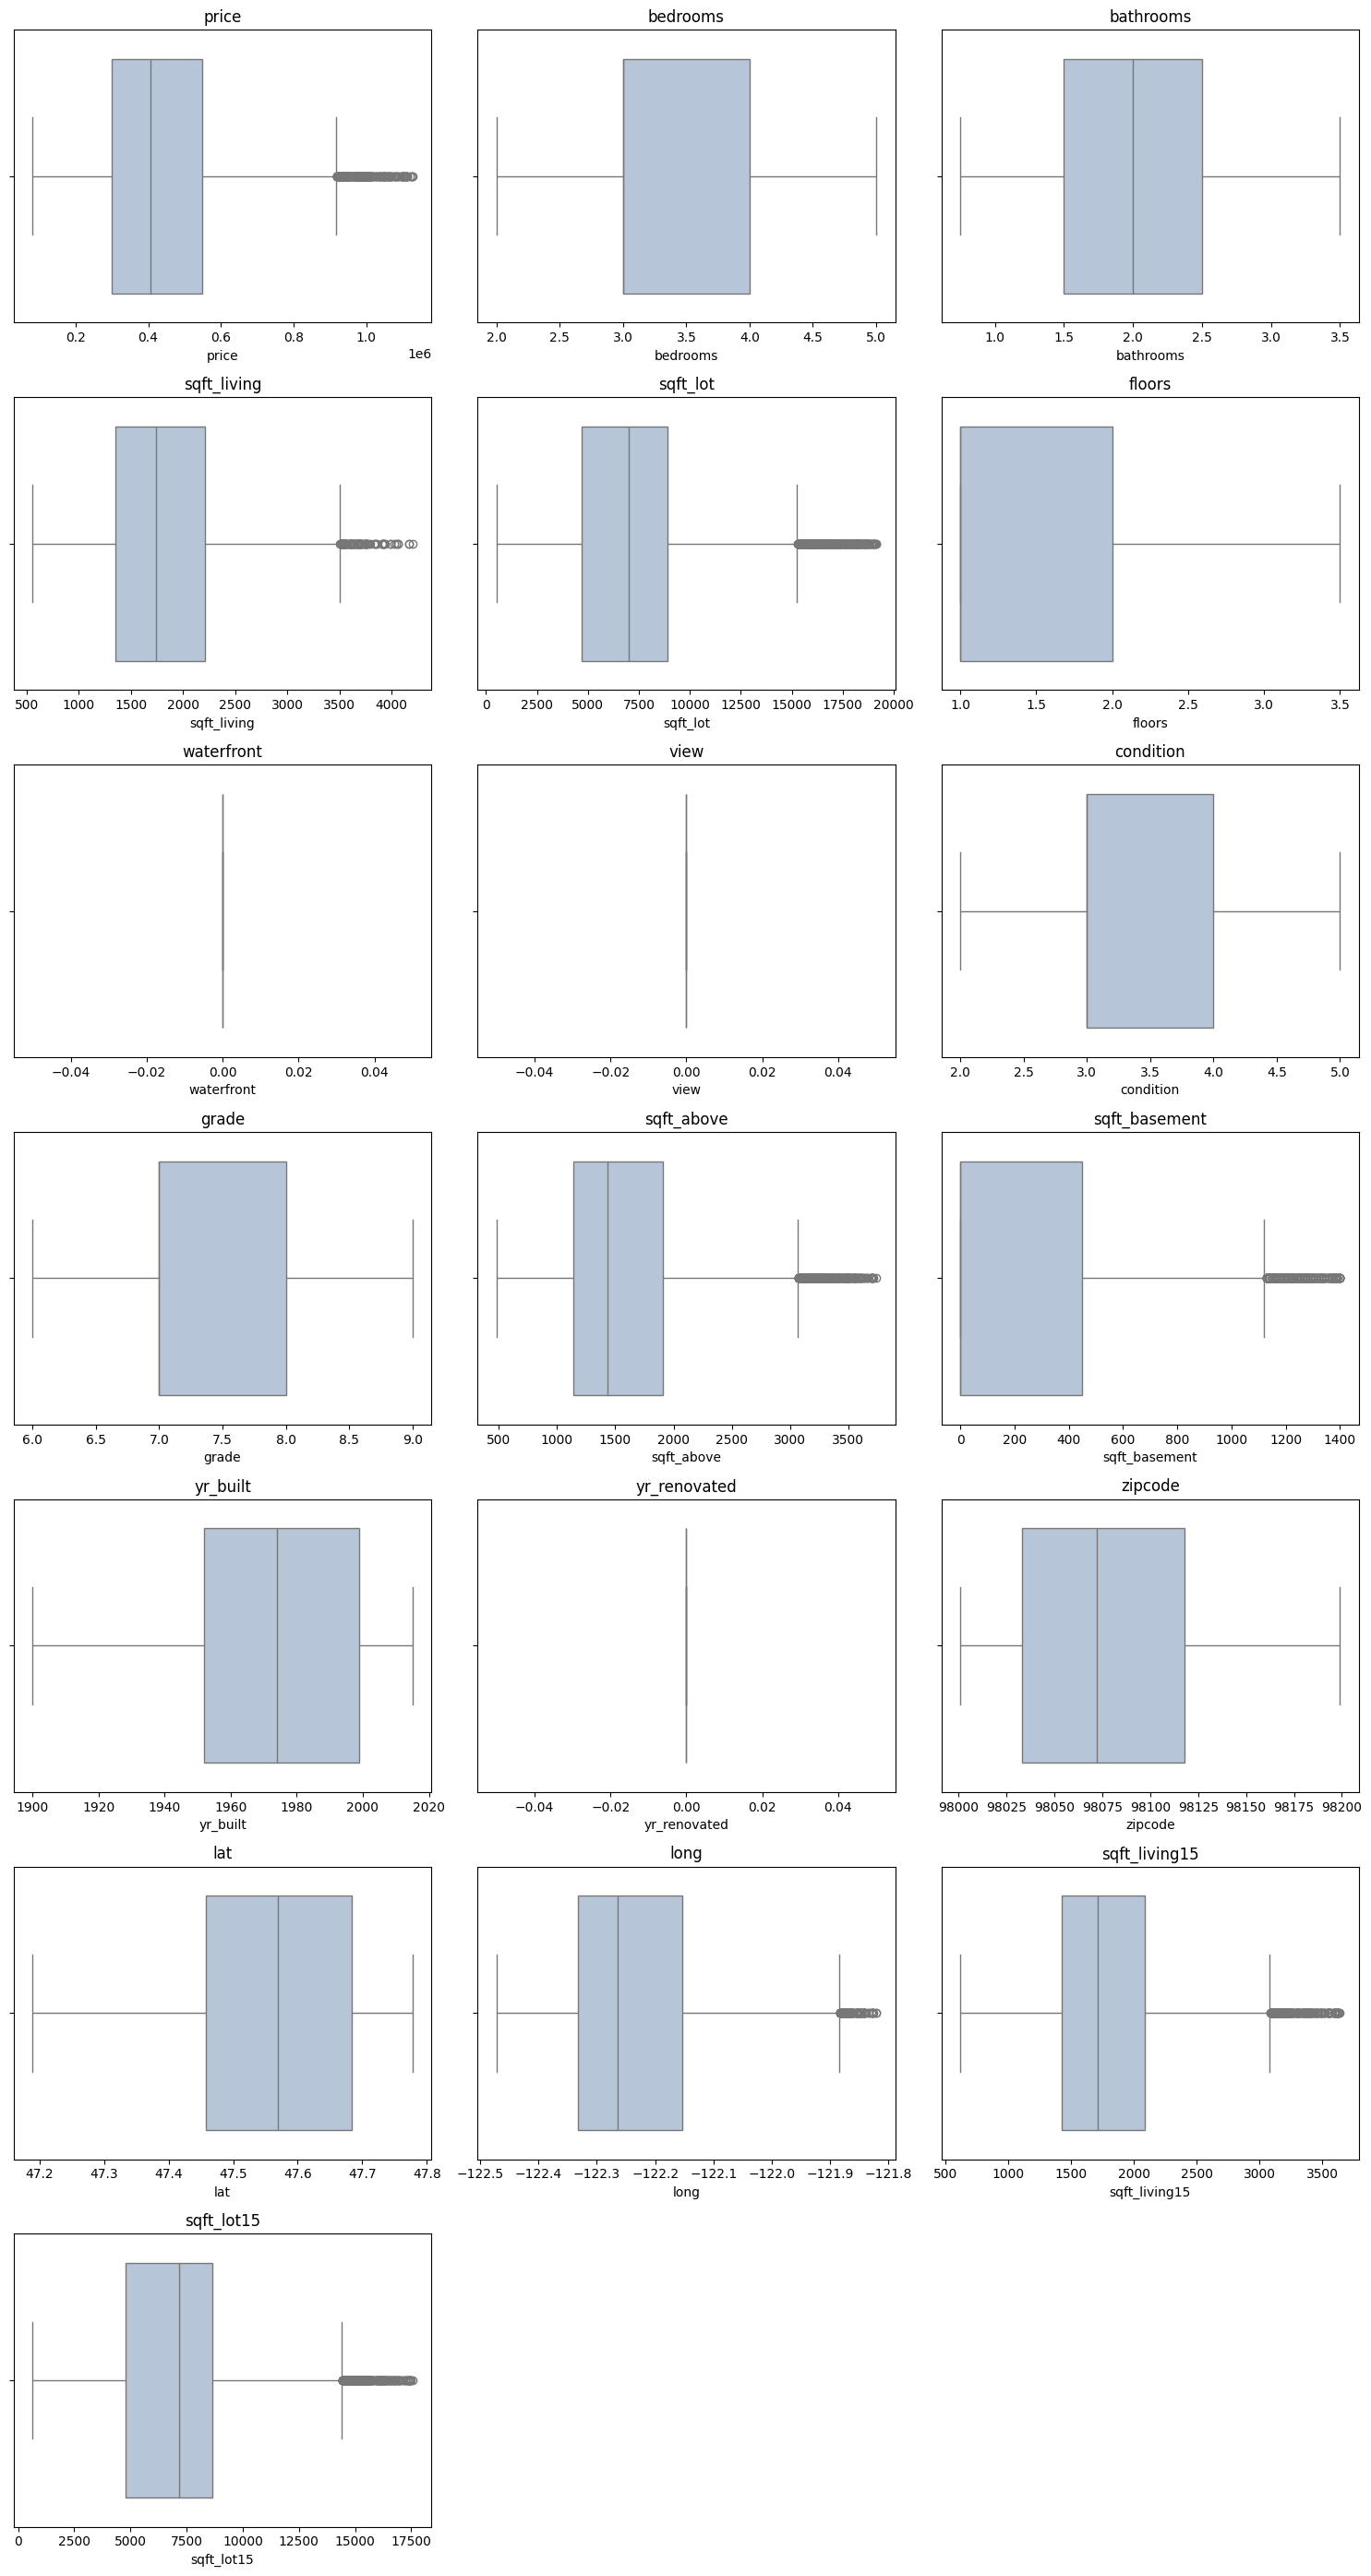

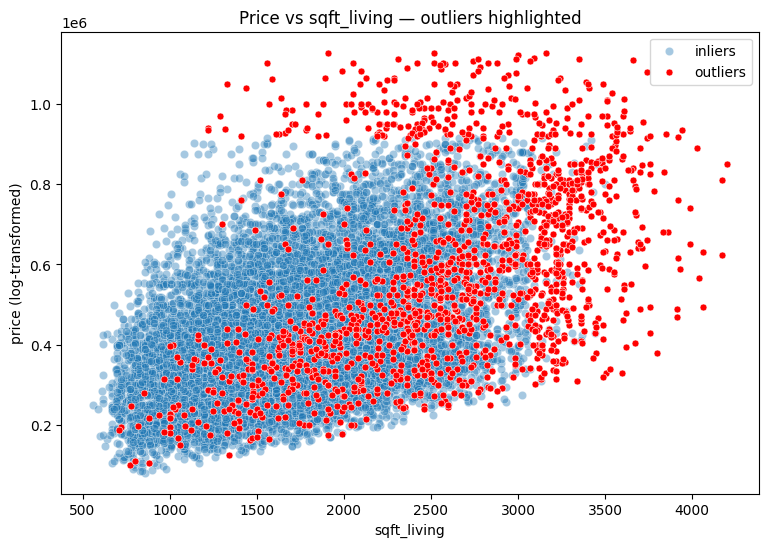

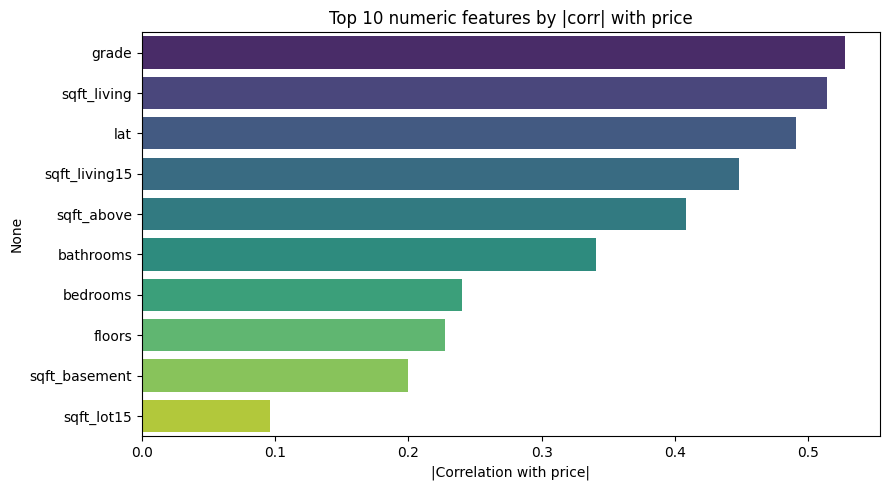

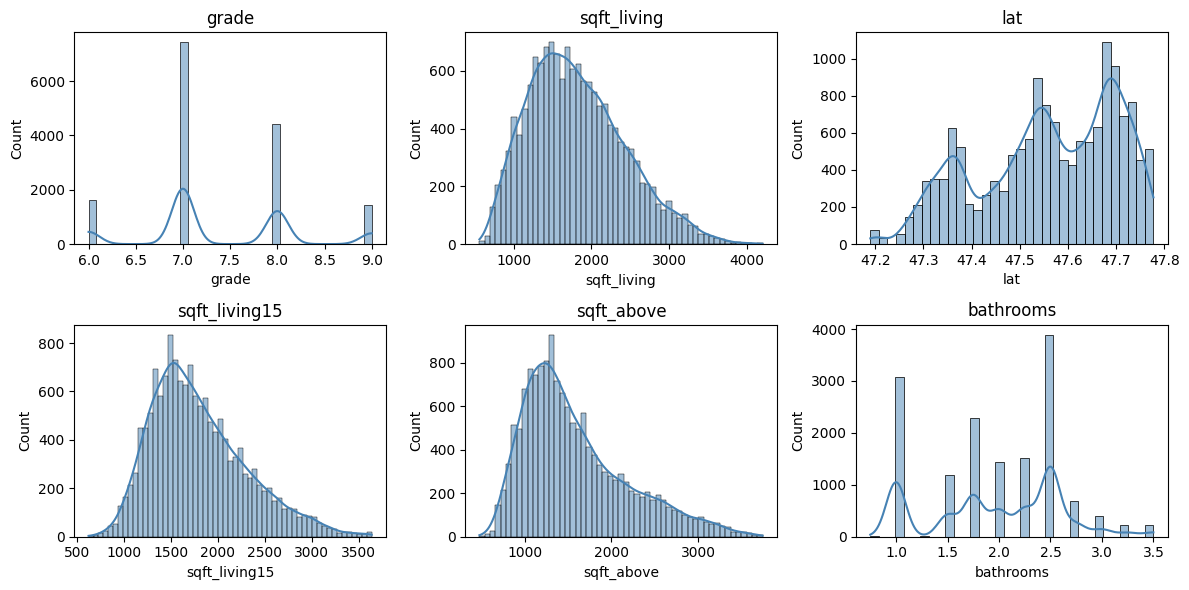

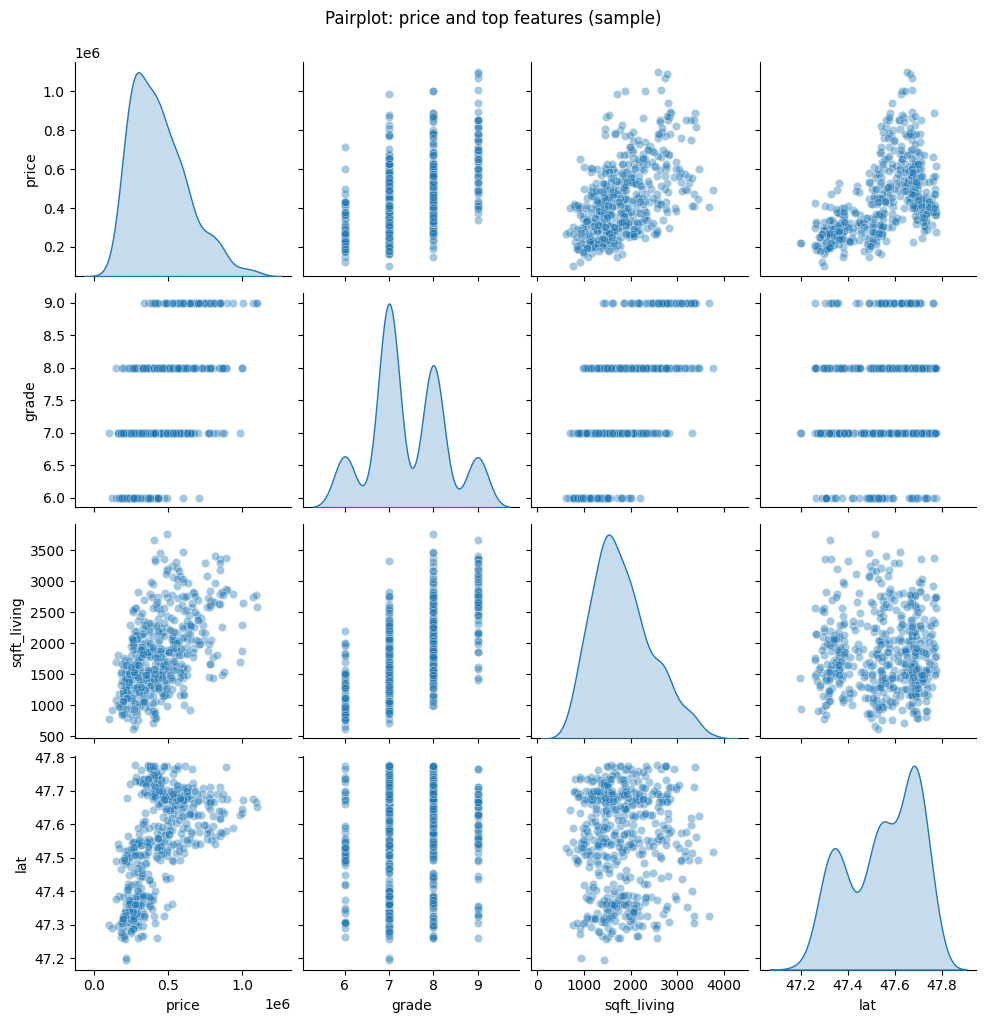

In [14]:
# Cell: Outlier detection and visualization (computes outlier mask, shows boxplots and scatter plots)
# This cell does NOT modify `df` (it uses the previously computed `outlier_mask` for visual analysis).
# ===== Outlier & Important-Features Visualization (no DataFrame modification) =====
# This cell computes outliers using the same IQR logic used above but does NOT modify `df`.
numeric_cols = df.select_dtypes(include=[np.number]).columns
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
# Row-level mask for any numeric column being an outlier
outlier_mask = ((df[numeric_cols] < lower) | (df[numeric_cols] > upper)).any(axis=1)
outliers = df[outlier_mask]
print(f"Total rows: {df.shape[0]}, Outlier rows: {outliers.shape[0]}")
print("Outlier counts per column:")
print(((df[numeric_cols] < lower) | (df[numeric_cols] > upper)).sum().sort_values(ascending=False))

# Boxplots for numeric columns (visualize spread and outliers)
cols = list(numeric_cols)
n = len(cols)
ncols = 3
nrows = (n + ncols - 1) // ncols
plt.figure(figsize=(5 * ncols, 4 * max(1, nrows)))
for i, col in enumerate(cols, 1):
    plt.subplot(nrows, ncols, i)
    sns.boxplot(x=df[col], color='lightsteelblue')
    plt.title(col)
plt.tight_layout()
plt.show()

# Scatter: price vs sqft_living (highlight outliers) if those cols exist
if 'sqft_living' in df.columns and 'price' in df.columns:
    plt.figure(figsize=(9,6))
    sns.scatterplot(x=df.loc[~outlier_mask,'sqft_living'], y=df.loc[~outlier_mask,'price'], alpha=0.4, label='inliers')
    sns.scatterplot(x=outliers['sqft_living'], y=outliers['price'], color='red', s=25, label='outliers')
    plt.xlabel('sqft_living')
    plt.ylabel('price (log-transformed)')
    plt.title('Price vs sqft_living — outliers highlighted')
    plt.legend()
    plt.show()

# --- Additional useful plots: correlation with price, histograms, feature importances, pairplot ---
# Correlation with price (absolute), top features
if 'price' in df.columns:
    corr_with_price = df[numeric_cols].corr()['price'].abs().drop('price', errors='ignore').sort_values(ascending=False)
    top_corr = corr_with_price.head(10)
    plt.figure(figsize=(9,5))
    sns.barplot(x=top_corr.values, y=top_corr.index, palette='viridis')
    plt.title('Top 10 numeric features by |corr| with price')
    plt.xlabel('|Correlation with price|')
    plt.tight_layout()
    plt.show()

    # Histograms for top correlated features
    top_feats = list(top_corr.index[:6])
    plt.figure(figsize=(4 * 3, 3 * 2))
    for i, f in enumerate(top_feats, 1):
        plt.subplot(2, 3, i)
        sns.histplot(df[f], kde=True, color='steelblue')
        plt.title(f)
    plt.tight_layout()
    plt.show()

# Model-based feature importances (if model is already trained in the notebook)
if 'model' in globals():
    try:
        feature_names = X.columns if 'X' in globals() else [c for c in df.columns if c != 'price']
        importances = getattr(model, 'feature_importances_', None)
        if importances is not None and len(importances) == len(feature_names):
            fi = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(10)
            plt.figure(figsize=(9,5))
            sns.barplot(x=fi.values, y=fi.index, palette='magma')
            plt.title('Top 10 Model Feature Importances')
            plt.xlabel('Importance')
            plt.tight_layout()
            plt.show()
        else:
            print('Model present but feature_importances_ not available or length mismatch; skipping model importances.')
    except Exception as e:
        print('Error plotting model importances:', e)

# Small pairplot of top 3 correlated features vs price (keeps it light)
if 'price' in df.columns and not corr_with_price.empty:
    pair_feats = list(corr_with_price.drop('price', errors='ignore').index[:3])
    if pair_feats:
        try:
            sns.pairplot(df[[ 'price'] + pair_feats].sample(min(500, len(df))), diag_kind='kde', plot_kws={'alpha':0.4})
            plt.suptitle('Pairplot: price and top features (sample)', y=1.02)
            plt.show()
        except Exception as e:
            print('Pairplot failed (too large or plotting issue):', e)

# End of extended visualization cell

=== Feature Distribution Statistics ===
                    mean     median        std  skew  kurtosis
price          438530.17  405000.00  180297.04  0.84      0.42
bedrooms            3.26       3.00       0.77  0.24     -0.27
bathrooms           1.97       2.00       0.65 -0.09     -0.82
sqft_living      1814.15    1740.00     614.64  0.55     -0.09
sqft_lot         6988.30    7020.00    3355.78  0.53      0.49
floors              1.47       1.00       0.55  0.77     -0.22
waterfront          0.00       0.00       0.00  0.00      0.00
view                0.00       0.00       0.00  0.00      0.00
condition           3.42       3.00       0.65  1.12      0.31
grade               7.38       7.00       0.81  0.32     -0.34
sqft_above       1585.19    1430.00     601.50  0.97      0.41
sqft_basement     228.96       0.00     353.24  1.32      0.50
yr_built         1971.72    1974.00      29.25 -0.45     -0.65
yr_renovated        0.00       0.00       0.00  0.00      0.00
zipcode        

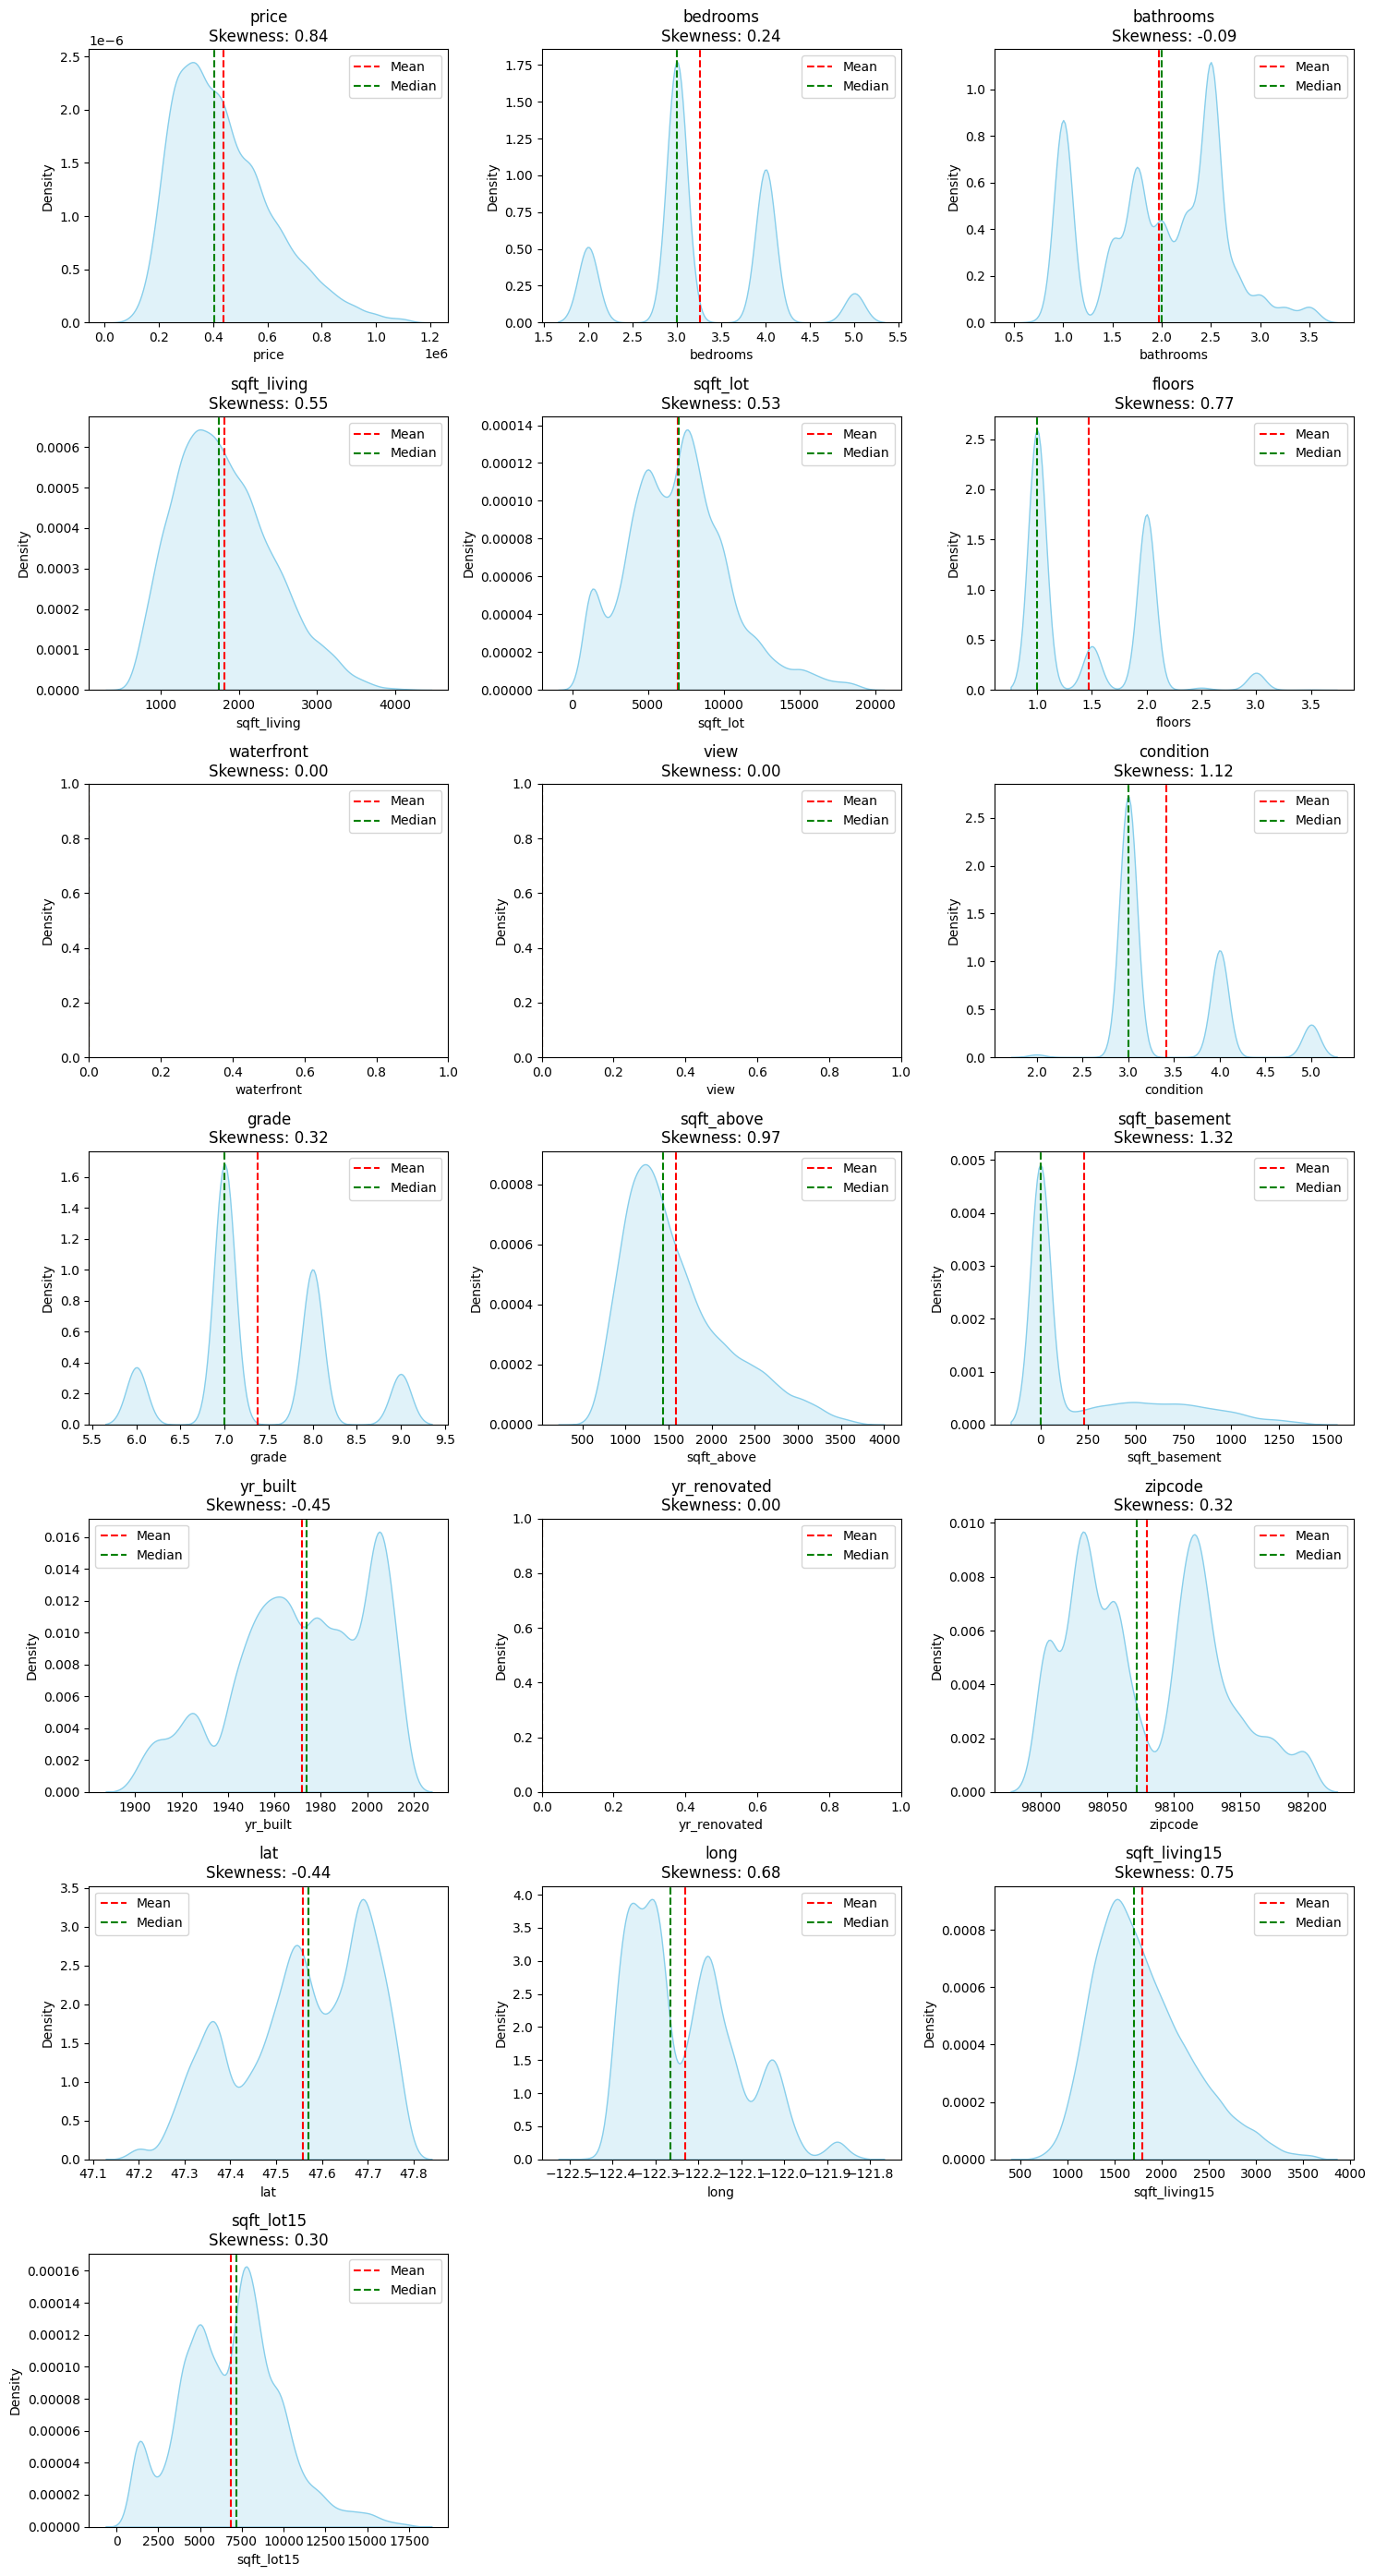


=== Feature Transformation Recommendations ===
- condition: High skewness (1.12). Consider:
  * Log transformation: np.log1p(x)
  * Square root transformation: np.sqrt(x)
- sqft_basement: High skewness (1.32). Consider:
  * Log transformation: np.log1p(x)
  * Square root transformation: np.sqrt(x)


In [15]:
# Cell: Feature distribution statistics and transformation suggestions.
# Computes summary stats and visualizations for numeric features and recommends transforms.
# ===== Enhanced Feature Distribution Analysis (no DataFrame modification) =====
# Compute distribution statistics for all numeric features
numeric_stats = pd.DataFrame({
    'mean': df[numeric_cols].mean(),
    'median': df[numeric_cols].median(),
    'std': df[numeric_cols].std(),
    'skew': df[numeric_cols].skew(),
    'kurtosis': df[numeric_cols].kurtosis()
}).round(2)

print("=== Feature Distribution Statistics ===")
print(numeric_stats)

# Plot distribution of all numeric features with skewness indication
n_features = len(numeric_cols)
n_cols = 3
n_rows = (n_features + n_cols - 1) // n_cols
plt.figure(figsize=(15, 4 * n_rows))

for idx, col in enumerate(numeric_cols, 1):
    plt.subplot(n_rows, n_cols, idx)
    
    # Distribution plot
    sns.kdeplot(data=df[col], fill=True, color='skyblue')
    plt.axvline(df[col].mean(), color='red', linestyle='--', label='Mean')
    plt.axvline(df[col].median(), color='green', linestyle='--', label='Median')
    
    # Add skewness annotation
    skew = df[col].skew()
    plt.title(f'{col}\nSkewness: {skew:.2f}')
    plt.legend()

plt.tight_layout()
plt.show()

# Print transformation recommendations
print("\n=== Feature Transformation Recommendations ===")
for col in numeric_cols:
    skew = df[col].skew()
    if abs(skew) > 1:
        print(f"- {col}: High skewness ({skew:.2f}). Consider:")
        if skew > 0:
            print("  * Log transformation: np.log1p(x)")
            print("  * Square root transformation: np.sqrt(x)")
        else:
            print("  * Exponential transformation: np.exp(x)")
            print("  * Square transformation: x²")

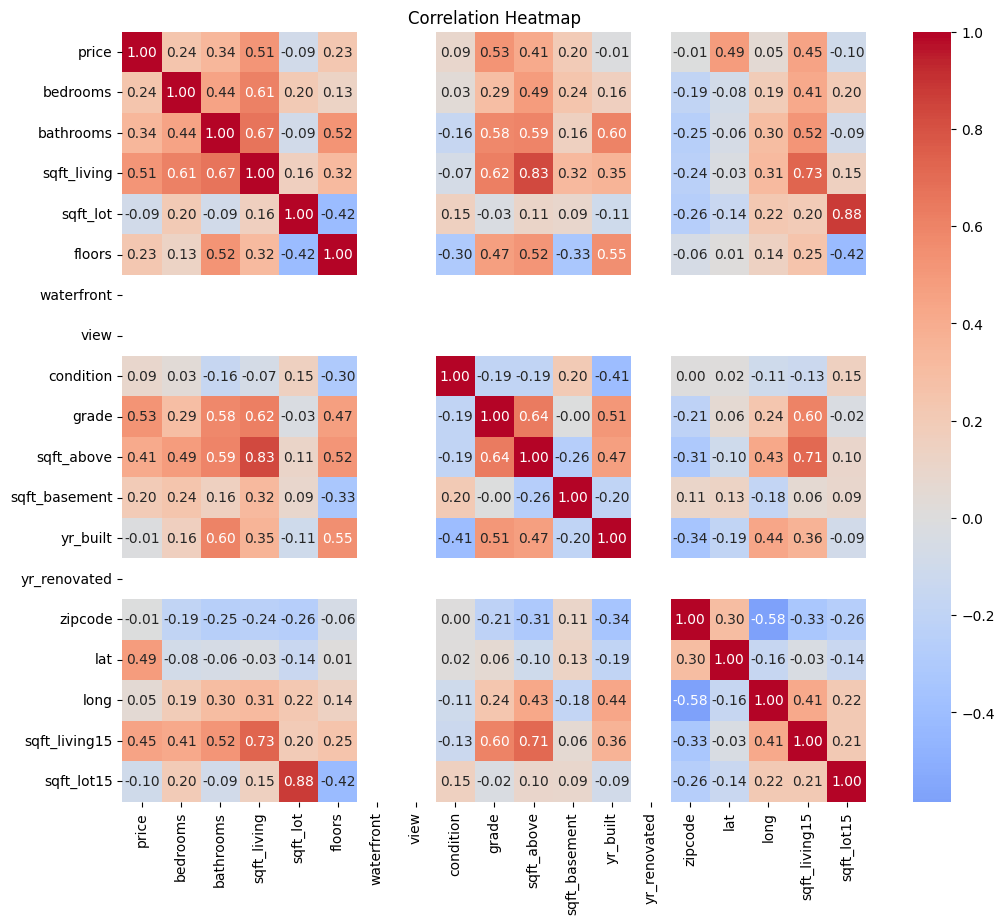


=== Highly Correlated Feature Pairs (|correlation| > 0.7) ===
sqft_lot ~ sqft_lot15: 0.882
sqft_living ~ sqft_above: 0.831
sqft_living ~ sqft_living15: 0.727
sqft_above ~ sqft_living15: 0.710


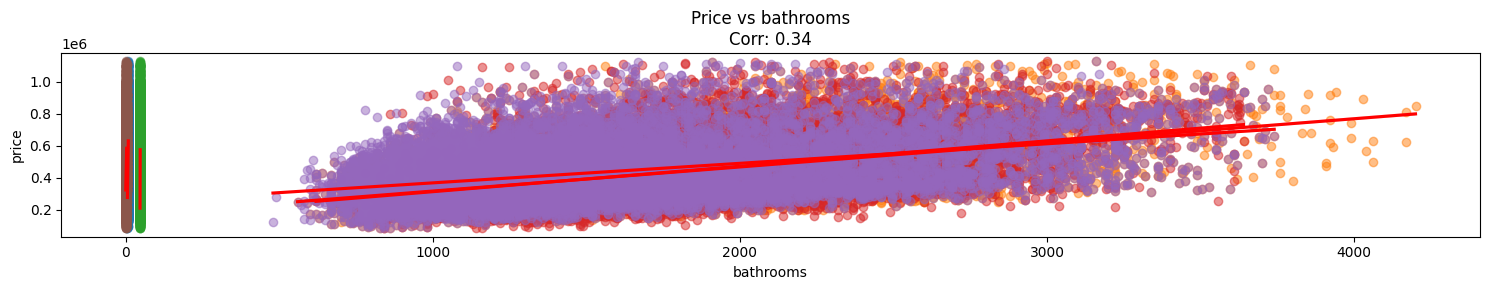

In [16]:
# Cell: Feature relationships, correlation matrix and highly correlated pairs.
# This helps identify multicollinearity and candidate features for interaction terms.
# ===== Feature Relationships and Interactions Analysis =====
# Recompute numeric columns to match the current DataFrame (prevents KeyError if columns were dropped)
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Compute and display enhanced correlation analysis
correlation = df[numeric_cols].corr()

# Create a regular correlation heatmap (simpler version)
plt.figure(figsize=(12, 10))
sns.heatmap(correlation, 
           cmap='coolwarm',
           center=0,
           annot=True,
           fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Find highly correlated feature pairs
high_corr_pairs = []
for i in range(len(correlation.columns)):
    for j in range(i+1, len(correlation.columns)):
        if abs(correlation.iloc[i, j]) > 0.7:
            high_corr_pairs.append((
                correlation.index[i], 
                correlation.columns[j], 
                correlation.iloc[i, j]
            ))

if high_corr_pairs:
    print("\n=== Highly Correlated Feature Pairs (|correlation| > 0.7) ===")
    for feat1, feat2, corr in sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True):
        print(f"{feat1} ~ {feat2}: {corr:.3f}")

# Visualize key relationships with price (if exists)
if 'price' in df.columns:
    # Get top 5 correlated features with price
    price_corr = correlation['price'].abs().sort_values(ascending=False)
    # Create scatter plots with regression lines
    plt.figure(figsize=(15, 3))
    for i, feature in enumerate(top_feats, 1):    
        sns.regplot(data=df, x=feature, y='price', scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})
    plt.title(f'Price vs {feature}\nCorr: {correlation.loc["price", feature]:.2f}')
    plt.tight_layout()
    plt.show()

=== Detailed Column Statistics ===
                 dtype  count unique_count missing missing_pct  zeros  \
price          float64  14934         2887       0         0.0      0   
bedrooms         int64  14934            4       0         0.0      0   
bathrooms      float64  14934           12       0         0.0      0   
sqft_living      int64  14934          645       0         0.0      0   
sqft_lot         int64  14934         6526       0         0.0      0   
floors         float64  14934            6       0         0.0      0   
waterfront       int64  14934            1       0         0.0  14934   
view             int64  14934            1       0         0.0  14934   
condition        int64  14934            4       0         0.0      0   
grade            int64  14934            4       0         0.0      0   
sqft_above       int64  14934          626       0         0.0      0   
sqft_basement    int64  14934          170       0         0.0   9474   
yr_built        

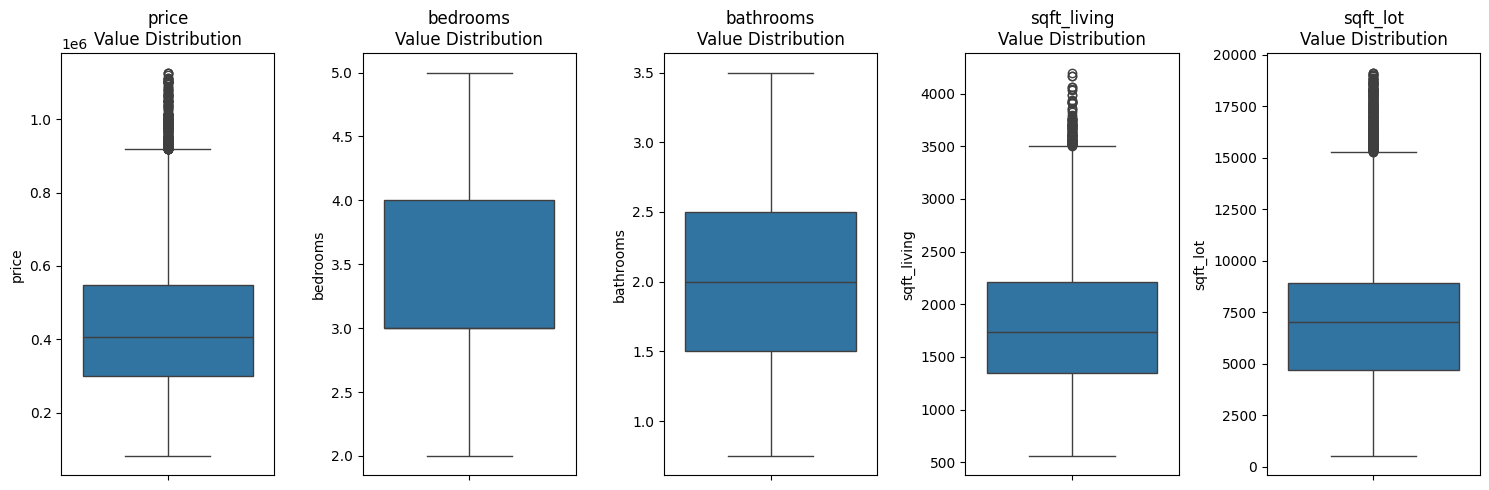

In [17]:
# Cell: Data quality checks and a helper to get column-level stats.
# Provides recommendations and prints detailed per-column statistics to inform preprocessing.
# ===== Data Quality and Preprocessing Insights =====
# Function to get detailed column info
def get_column_analysis(df, column):
    stats = {
        'dtype': str(df[column].dtype),
        'count': len(df[column]),
        'unique_count': df[column].nunique(),
        'missing': df[column].isnull().sum(),
        'missing_pct': (df[column].isnull().sum() / len(df[column])) * 100,
        'zeros': (df[column] == 0).sum() if pd.api.types.is_numeric_dtype(df[column]) else None,
        'zeros_pct': ((df[column] == 0).sum() / len(df[column])) * 100 if pd.api.types.is_numeric_dtype(df[column]) else None,
        'min': df[column].min() if pd.api.types.is_numeric_dtype(df[column]) else None, 'max': df[column].max() if pd.api.types.is_numeric_dtype(df[column]) else None
    }
    return pd.Series(stats)

# Compute detailed statistics for all columns
detailed_stats = pd.DataFrame({col: get_column_analysis(df, col) for col in df.columns}).T

print("=== Detailed Column Statistics ===")
print(detailed_stats)

# Identify potential data quality issues
print("\n=== Data Quality Insights ===")

# Check for columns with high percentage of zeros
numeric_cols = df.select_dtypes(include=[np.number]).columns
high_zeros = [(col, (df[col] == 0).mean() * 100) for col in numeric_cols 
              if (df[col] == 0).mean() > 0.1]
if high_zeros:
    print("\nColumns with high percentage of zeros (>10%):")
    for col, pct in sorted(high_zeros, key=lambda x: x[1], reverse=True):
        print(f"- {col}: {pct:.1f}%")

# Value range analysis
print("\n=== Value Range Analysis ===")
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    print(f"\n{col}:")
    print(f"- Range: [{df[col].min():.2f}, {df[col].max():.2f}]")
    print(f"- IQR: {iqr:.2f}")
    print(f"- 95% range: [{df[col].quantile(0.025):.2f}, {df[col].quantile(0.975):.2f}]")

# Preprocessing recommendations
print("\n=== Preprocessing Recommendations ===")
print("\nBased on the analysis, consider:")
for col in numeric_cols:
    skew = df[col].skew()
    zeros_pct = (df[col] == 0).mean() * 100
    range_ratio = df[col].max() / df[col].min() if df[col].min() != 0 else float('inf')
    
    recommendations = []
    if abs(skew) > 1:
        recommendations.append("- Skewness correction (e.g., log transform)")
    if zeros_pct > 10:
        recommendations.append("- Handle high frequency of zeros")
    if range_ratio > 1000:
        recommendations.append("- Scale to handle large value range")
    
    if recommendations:
        print(f"\n{col}:")
        for rec in recommendations:
            print(f"  {rec}")

# Plot value distributions for selected features
plt.figure(figsize=(15, 5))
for i, col in enumerate(numeric_cols[:5], 1):  # First 5 numeric columns
    plt.subplot(1, 5, i)
    sns.boxplot(y=df[col])
    plt.title(f'{col}\nValue Distribution')
plt.tight_layout()
plt.show()

In [18]:
# Cell: Feature engineering — create derived features like house age and renovation flag,
# transform the target variable (log1p) to reduce skewness, and split into X/y.
# =============================================
# STEP 3: Feature Engineering
# =============================================

# Create new features
df['house_age'] = 2025 - df['yr_built']
df['recent_renovation'] = np.where(df['yr_renovated'] > 0, 1, 0)
df = df.drop(['yr_built', 'yr_renovated'], axis=1)

# Log-transform the target to reduce skewness
df['price'] = np.log1p(df['price'])

# Feature/target split
X = df.drop('price', axis=1)
y = df['price']


In [19]:
# Cell: Preserve original price column before any further transformation
# This duplicates the price column (already transformed) to keep an original backup if needed.
# Save original price before transformation
df['original_price'] = df['price'].copy()

In [20]:
# Cell: Train-test split and feature scaling
# Splits data and fits a StandardScaler on training data to avoid leakage.
# =============================================
# STEP 4: Split & Scaling
# =============================================

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [21]:
# Cell: Train an XGBoost regressor on the scaled training data
# Adjust hyperparameters as needed; here we use modest settings for demonstration.
# =============================================
# STEP 5: Train Model
# =============================================

model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

model.fit(X_train_scaled, y_train)
print("✅ Model training complete.")


✅ Model training complete.


In [22]:
# Cell: Evaluate the trained model on the test set and save metrics to `metrics.json`.
# This computes common regression metrics and persists them for later review.
# =============================================
# STEP 6: Evaluate Model
# =============================================

y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

# Save metrics
metrics = {
    'MAE': mae,
    'MSE': mse,
    'RMSE': rmse,
    'R2': r2
}

with open('metrics.json', 'w') as f:
    json.dump(metrics, f, indent=4)


MAE  : 0.1045
MSE  : 0.0208
RMSE : 0.1442
R²   : 0.8760


In [23]:
# Cell: Persist the trained model and fitted scaler to disk for use by the Streamlit app
# Model and scaler are saved under the `model/` directory.
# =============================================
# STEP 7: Save Model and Scaler
# =============================================

joblib.dump(model, 'model/model.pkl')
joblib.dump(scaler, 'model/scaler.pkl')

print("💾 Model and Scaler saved successfully!")


💾 Model and Scaler saved successfully!


In [24]:
# Placeholder cell — reserved for future code or notes (no action).

In [25]:
# Placeholder cell — reserved for future code or notes (no action).

In [26]:
# Placeholder cell — reserved for future code or notes (no action).

In [27]:
# Placeholder cell — reserved for future code or notes (no action).